# University rankings: research, teaching and international reach

This report uses the Times Higher Education table to compare institutions within one ranking system. It focuses on the latest year in the uploaded file, then checks research-score changes for institutions observed at both ends of the period.

## Data and scope

Source: [world-university-rankings](https://www.kaggle.com/datasets/mylesoneill/world-university-rankings). This report uses the uploaded snapshot, not live data.

`timesData.csv` has one institution-year per row. `university_name` and `country` identify the institution; `year` identifies the edition. `teaching`, `research`, `citations`, `income`, `international` and `total_score` are ranking scores. `world_rank` may contain a tied rank or a range. `num_students` is enrolment; `student_staff_ratio` is students per staff member; `international_students` is a percentage; `female_male_ratio` is a text ratio. A dash is unavailable data, not a zero score.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("timesData.csv"))
print(f"Raw data: {raw.shape[0]:,} rows, {raw.shape[1]} columns")
assert raw.shape[0]>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))

Raw data: 2,603 rows, 14 columns


,world_rank,university_name,country,teaching,international,research,citations,income,total_score,num_students,student_staff_ratio,international_students,female_male_ratio,year
0,1,Harvard University,United States of America,99.700,72.4,98.700,98.800,34.5,96.1,"20,152",8.900,25%,NaN,2011
1,2,California Institute of Technology,United States of America,97.700,54.6,98.000,99.900,83.7,96.0,"2,243",6.900,27%,33 : 67,2011
2,3,Massachusetts Institute of Technology,United States of America,97.800,82.3,91.400,99.900,87.5,95.6,"11,074",9.000,33%,37 : 63,2011
3,4,Stanford University,United States of America,98.300,29.5,98.100,99.200,64.3,94.3,"15,596",7.800,22%,42 : 58,2011
4,5,Princeton University,United States of America,90.900,70.3,95.400,99.900,-,94.2,"7,929",8.400,27%,45 : 55,2011


,missing
world_rank,0
university_name,0
country,0
teaching,0
international,0
research,0
citations,0
income,0
total_score,0
num_students,59


Latest edition: 2016; institutions: 800; duplicate institution-year keys: 0


,count,mean,std,min,25%,50%,75%,max
teaching,800.000,31.584,14.985,9.900,21.000,27.000,37.500,95.600
research,800.000,28.129,19.532,2.900,14.350,22.100,35.525,99.000
citations,800.000,51.310,27.045,1.200,27.525,50.300,74.900,100.000
total_score,200.000,62.520,12.041,48.800,52.900,57.950,69.625,95.200
student_staff_ratio,793.000,19.116,12.522,0.600,12.300,16.600,22.400,162.600
international_pct,790.000,12.703,10.676,0.000,5.000,10.000,18.000,82.000


,ranked_institutions
year,
2011,200
2012,402
2013,400
2014,400
2015,401
2016,800


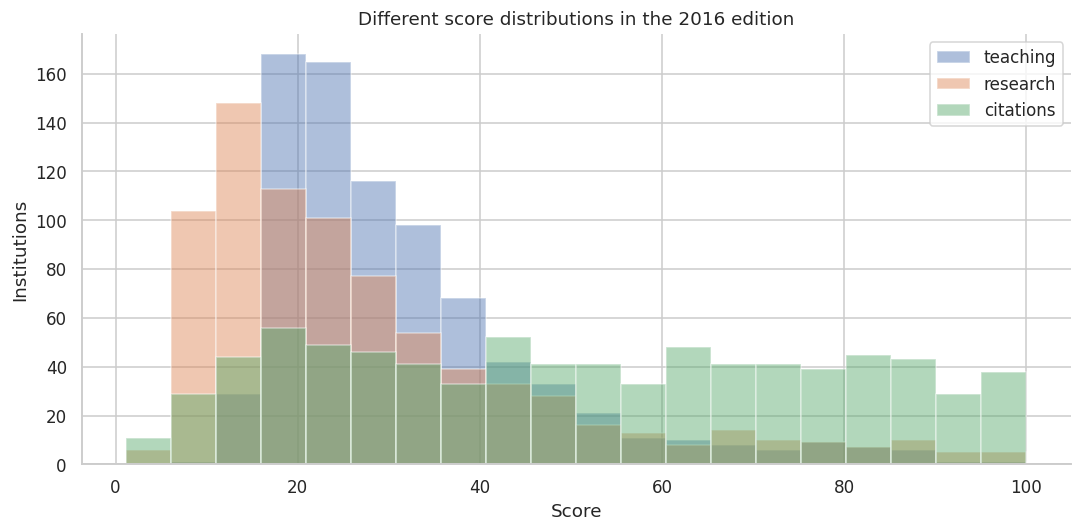

In [3]:
df = raw.drop_duplicates().copy()
for col in ["university_name","country"]:
    df[col] = df[col].astype("string").str.strip()
for col in ["teaching","research","citations","income","international","total_score","student_staff_ratio"]:
    df[col] = pd.to_numeric(df[col],errors="coerce")
df["num_students"] = pd.to_numeric(df.num_students.astype(str).str.replace(",","",regex=False),errors="coerce")
df["international_pct"] = pd.to_numeric(df.international_students.astype(str).str.replace("%","",regex=False),errors="coerce")
df.loc[~df.international_pct.between(0,100),"international_pct"] = np.nan
latest_year = int(df.year.max())
latest = df[df.year.eq(latest_year)].copy()
print(f"Latest edition: {latest_year}; institutions: {len(latest):,}; duplicate institution-year keys: {df.duplicated(['university_name','year']).sum()}")
display(latest[["teaching","research","citations","total_score","student_staff_ratio","international_pct"]].describe().T)
display(df.groupby("year").size().rename("ranked_institutions").to_frame())
latest[["teaching","research","citations"]].plot.hist(alpha=.45,bins=20)
plt.xlabel("Score"); plt.ylabel("Institutions"); plt.title(f"Different score distributions in the {latest_year} edition")
plt.tight_layout(); plt.show()

## 1. Which countries have the most listed institutions?

`value_counts()` counts institutions in the latest edition. This measures representation in the table, not the average quality of an entire national education system.

,institutions
country,
United States of America,146
United Kingdom,77
Japan,41
Germany,37
China,37
Italy,34
Australia,31
France,27
Spain,25


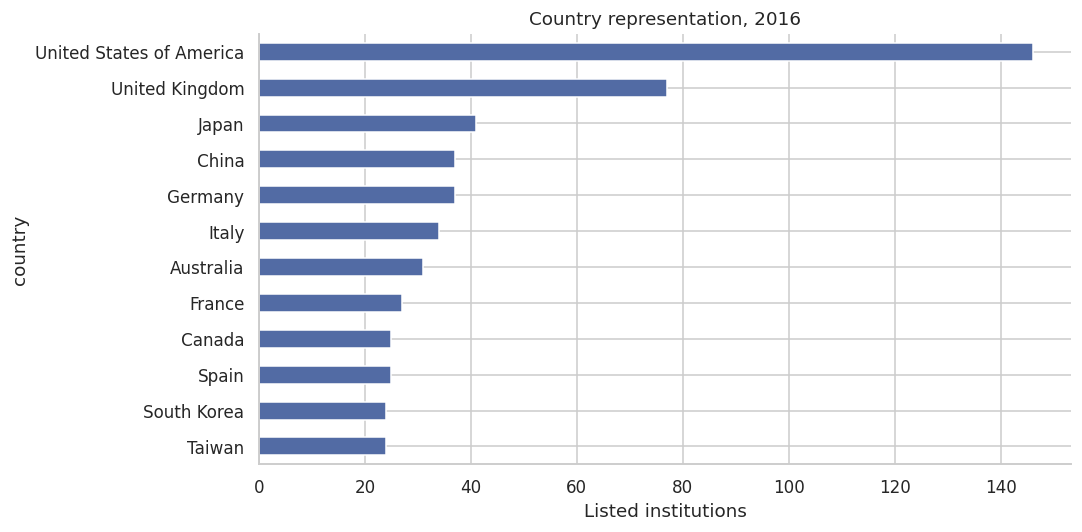

In [4]:
countries = latest.country.value_counts()
display(countries.head(15).to_frame("institutions"))
countries.head(12).sort_values().plot.barh(color="#526ba4")
plt.xlabel("Listed institutions"); plt.title(f"Country representation, {latest_year}"); plt.tight_layout(); plt.show()

**Answer.** United States of America has the most listed institutions (146), or 18.2% of this edition. Country size and ranking coverage affect this count; it is not a population-adjusted comparison.

## 2. Which institutions lead among those with a published total score?

`dropna()` removes entries without a numeric total score for this ranking only. Lower-ranked institutions often have rank bands and no numeric total, so this is a comparison of the scored subset.

,university_name,country,world_rank,total_score,teaching,research
1803,California Institute of Technology,United States of America,1,95.200,95.600,97.600
1804,University of Oxford,United Kingdom,2,94.200,86.500,98.900
1805,Stanford University,United States of America,3,93.900,92.500,96.200
1806,University of Cambridge,United Kingdom,4,92.800,88.200,96.700
1807,Massachusetts Institute of Technology,United States of America,5,92.000,89.400,88.600
1808,Harvard University,United States of America,6,91.600,83.600,99.000
1809,Princeton University,United States of America,7,90.100,85.100,91.900
1810,Imperial College London,United Kingdom,8,89.100,83.300,88.500
1811,ETH Zurich – Swiss Federal Institute of Techno...,Switzerland,9,88.300,77.000,95.000
1812,University of Chicago,United States of America,10,87.900,85.700,88.900


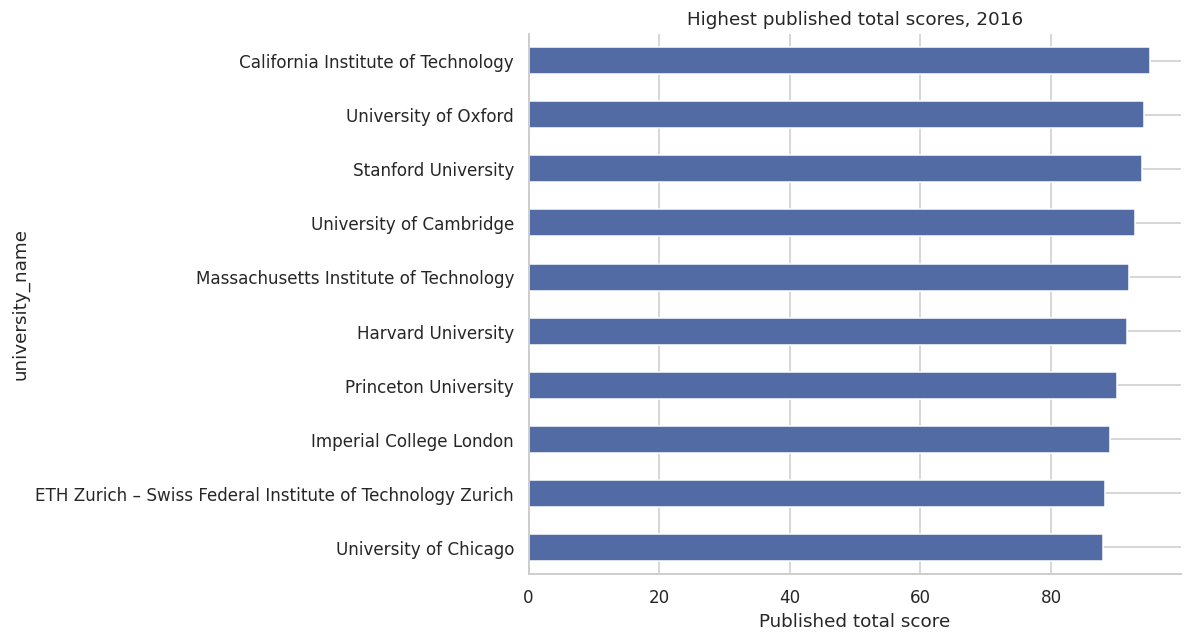

In [5]:
leaders = latest.dropna(subset=["total_score"]).nlargest(10,"total_score")
display(leaders[["university_name","country","world_rank","total_score","teaching","research"]])
leaders.set_index("university_name").total_score.sort_values().plot.barh(color="#526ba4",figsize=(11,6))
plt.xlabel("Published total score"); plt.title(f"Highest published total scores, {latest_year}"); plt.tight_layout(); plt.show()

**Answer.** California Institute of Technology has the highest published total score (95.2). Numeric total scores are available for 200 of 800 institutions, so a score-based chart does not represent every listed university.

## 3. How closely are teaching and research scores related?

`corr(method="spearman")` measures whether higher scores in one column tend to accompany higher scores in another. Pairwise complete observations are used. An association between ranking components does not show that one causes another.

,teaching,research,citations,international,income
teaching,1.000,0.806,0.554,0.278,0.404
research,0.806,1.000,0.633,0.424,0.513
citations,0.554,0.633,1.000,0.534,0.190
international,0.278,0.424,0.534,1.000,0.043
income,0.404,0.513,0.190,0.043,1.000


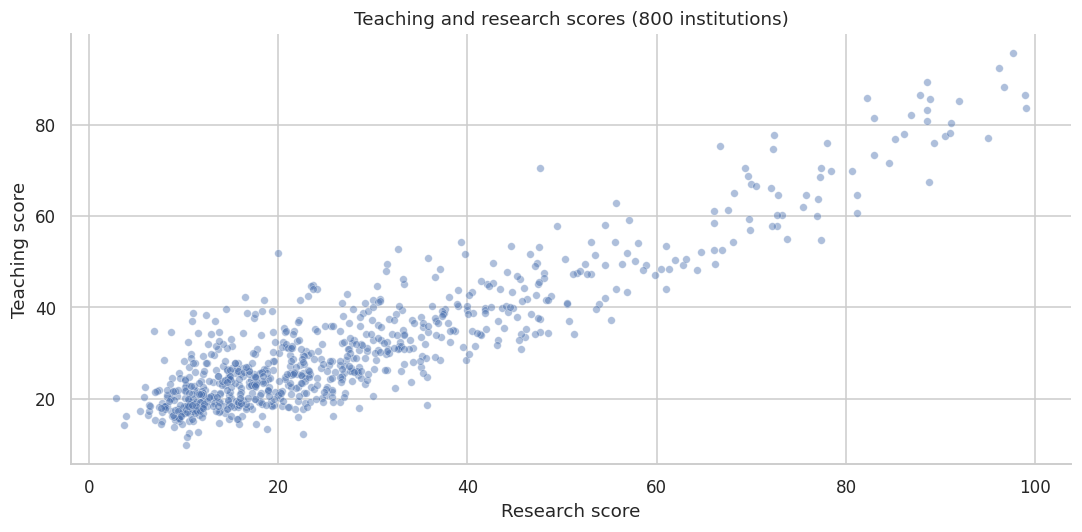

In [6]:
paired = latest.dropna(subset=["teaching","research"])
rho = paired.teaching.corr(paired.research,method="spearman")
display(latest[["teaching","research","citations","international","income"]].corr(method="spearman"))
sns.scatterplot(data=paired,x="research",y="teaching",alpha=.45,s=25)
plt.title(f"Teaching and research scores ({len(paired):,} institutions)")
plt.xlabel("Research score"); plt.ylabel("Teaching score"); plt.tight_layout(); plt.show()

**Answer.** Teaching and research have a Spearman correlation of 0.806 across 800 institutions with both scores. This is a descriptive relationship between components of the same ranking system, rather than independent evidence about teaching outcomes.

## 4. How does international student share vary across countries?

The comparison includes countries with at least ten nonmissing international-student percentages. `median()` reduces the influence of unusual institutions, and the table exposes the sample size behind each country result.

,count,median,mean
country,,,
United Kingdom,75,27.000,27.680
Australia,31,26.000,25.516
Switzerland,10,23.000,28.400
France,27,17.000,17.259
Canada,25,15.000,15.080
Netherlands,13,12.000,16.769
Germany,37,12.000,12.730
Sweden,10,12.000,12.400
United States of America,145,11.000,12.262


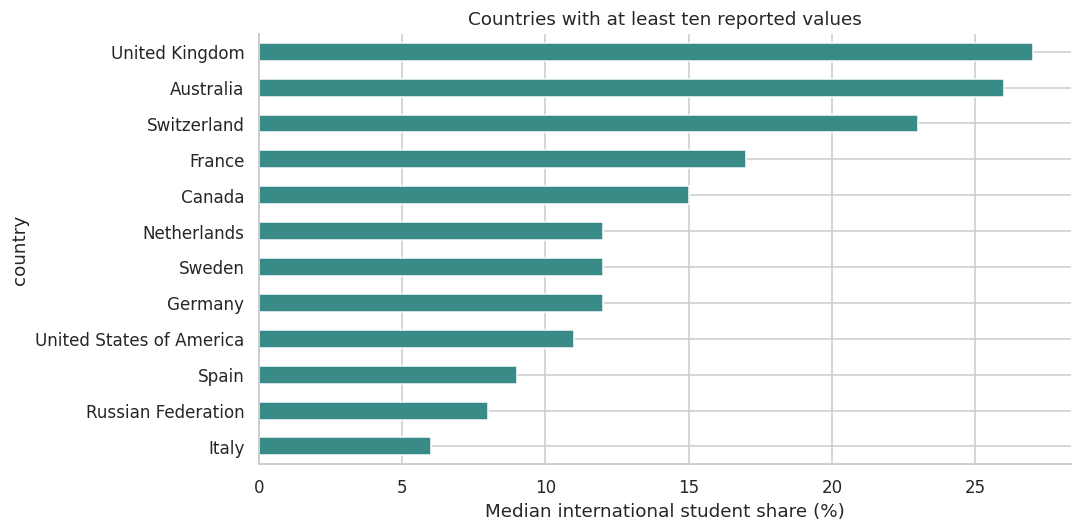

In [7]:
intl = latest.groupby("country").international_pct.agg(["count","median","mean"])
eligible = intl[intl["count"]>=10].sort_values("median",ascending=False)
display(eligible)
eligible["median"].head(12).sort_values().plot.barh(color="#388b86")
plt.xlabel("Median international student share (%)"); plt.title("Countries with at least ten reported values")
plt.tight_layout(); plt.show()

**Answer.** Among countries meeting the ten-observation rule, United Kingdom has the highest median international student share (27.0%), based on 75 institutions. Institutions with missing percentages are not treated as having zero international students.

## 5. Which matched institutions increased their research scores most?

`pivot()` places years in columns, allowing a comparison of the same institution at the beginning and end. This avoids comparing two changing lists as though they were a fixed cohort. Changes can still reflect ranking methods and reporting, as well as institutional performance.

year,2011,2016,change
university_name,,,
Humboldt University of Berlin,44.500,77.000,32.500
London School of Economics and Political Science,56.200,80.600,24.400
University of Tübingen,36.300,59.800,23.500
Technical University of Munich,43.200,66.000,22.800
Heidelberg University,47.500,69.600,22.100
New York University,50.700,72.300,21.600
King’s College London,54.500,75.800,21.300
LMU Munich,57.500,77.400,19.900
Monash University,38.800,58.500,19.700


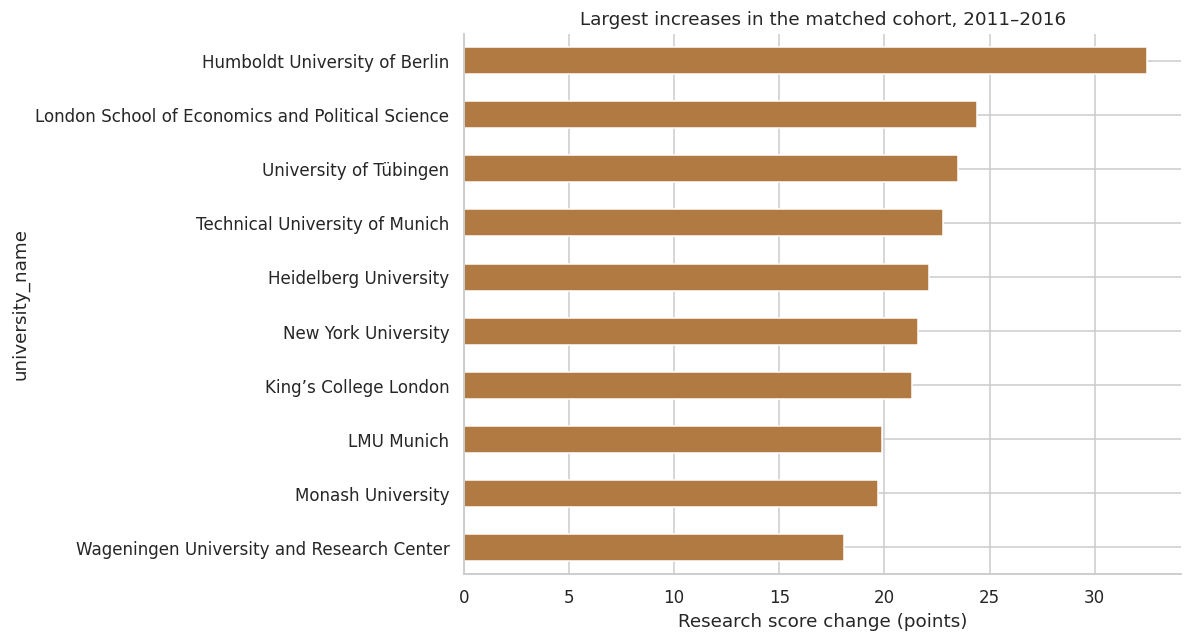

In [8]:
first_year = int(df.year.min())
panel = df.pivot(index="university_name",columns="year",values="research")
matched = panel[[first_year,latest_year]].dropna().copy()
matched["change"] = matched[latest_year]-matched[first_year]
gains = matched.nlargest(10,"change")
display(gains)
gains.change.sort_values().plot.barh(color="#b17a43",figsize=(11,6))
plt.xlabel("Research score change (points)"); plt.title(f"Largest increases in the matched cohort, {first_year}–{latest_year}")
plt.tight_layout(); plt.show()

**Answer.** 198 institutions have research scores in both 2011 and 2016. Humboldt University of Berlin has the largest increase within this matched group (32.5 points). This result does not include institutions that entered the ranking later or changed names.